# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Щербан Ярина Олегівна'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-32'      # напр. 'КН-31'
ВАРІАНТ = 18     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 18 · Щербан Ярина Олегівна, ШІ-32, «Longer Boats»
Підприємство «Longer Boats» виготовляє яхти. Одиниця виміру плану: шт./місяць.

                       Sting  Ray  Breaker  Marlin  ЗАПАС
Склопластик, м²            2    3        0       1   1217
Столярний цех, год         0    6        1       6    668
Фарбувальний цех, год      1    0        4       1    923
Такелаж, компл.            2    6        3       4   1040
Ділянка добудови, год      3    1        6       5    619

                    Sting  Ray  Breaker  Marlin
Прибуток з одиниці     66   54       18      66

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Ділянка добудови, год
  ціна:   34.9 за одиницю
  обсяг:  до 100 одиниць


In [3]:
import matplotlib.pyplot as plt
# try:
#     import pulp
#     ПУЛП = True
# except ImportError:
#     ПУЛП = False
#     print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

>Змінні рішення: кількість яхт кожної моделі, що випускаються за місяць, шт./місяць
>
>* x₁ - Sting
>* x₂ - Ray
>* x₃ - Breaker
>* x₄ - Marlin

>Цільова функція: місячний прибуток
>
>* F = 66*x₁ + 54*x₂ + 18*x₃ + 66*x₄ -> max

>Обмеження:
>
>* 2*x₁ + 3*x₂ + 0*x₃ + 1*x₄ ≤ 1217   (склопластик, м²)
>* 0*x₁ + 6*x₂ + 1*x₃ + 6*x₄ ≤ 668    (столярний цех, год)
>* 1*x₁ + 0*x₂ + 4*x₃ + 1*x₄ ≤ 923    (фарбувальний цех, год)
>* 2*x₁ + 6*x₂ + 3*x₃ + 4*x₄ ≤ 1040   (такелаж, компл.)
>* 3*x₁ + 1*x₂ + 6*x₃ + 5*x₄ ≤ 619    (ділянка добудови, год)

>Невід'ємність:
>
>* x₁, x₂, x₃, x₄ ≥ 0


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**

>Запас ресурсу задає зовнішнє обмеження, яке підприємство на момент планування не контролює, тоді як змінна рішення - це те, що підприємство обирає саме, наприклад скільки яхт кожної моделі випустити.
>Запас входить у модель як задане число в правій частині обмеження, і обмеження при цьому чинне: воно визначає, які плани допустимі. Якщо ми в процесі планування змінюватимемо запаси, ми не розв'язуватимемо задачу, а створюватимемо нову. Краще скористатись аналізом чутливості: тіньова ціна покаже, як оптимум реагує на зміну якогось з обмежень.

>Якби ресурс можна було докупити в будь-якій кількості, тоді запас став би змінною рішення і це би вплинуло на модель таким чином:
>
>Обмеження набуло б такого вигляду :  Σⱼ aᵢⱼ·xⱼ ≤ bᵢ + yᵢ
>Цільова функція :  F = Σ cⱼ·xⱼ − Σ pᵢ·yᵢ -> max
>
>де pᵢ - ціна одиниці ресурсу, який ми докуповуємо,  yᵢ - кількість ресурсу, який докуповуємо.
>
>І чисто теоретично це мало б оптимізовувати модель - поки тіньова ціна ресурсу перевищує ціну закупівлі ми можемо максимізувати прибуток, проте задача може стати необмеженою.

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

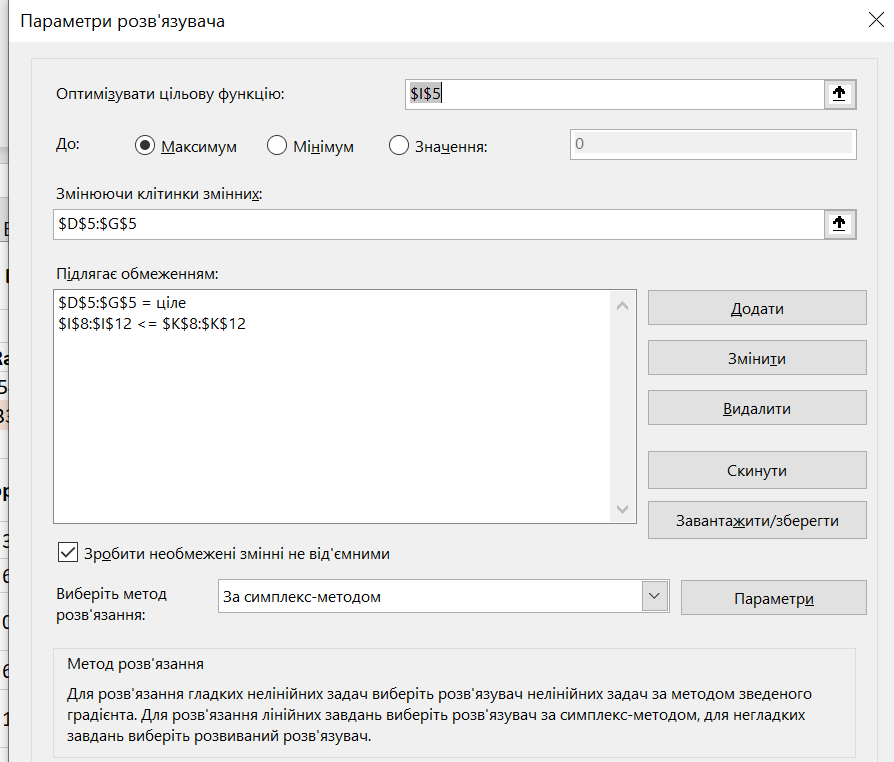

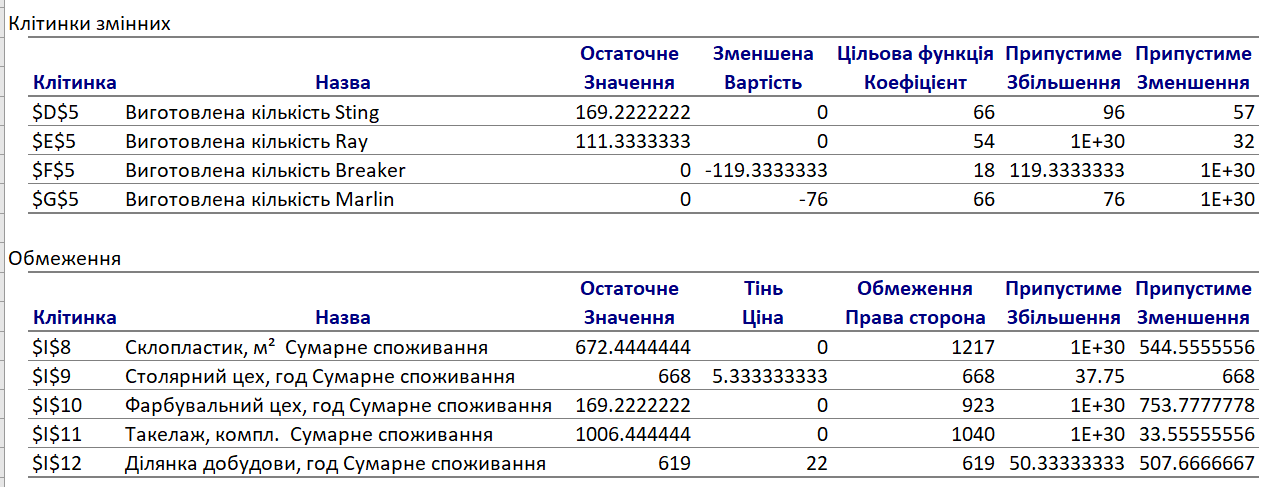

In [4]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН    = [169.222222222222, 111.333333333333, 0, 0]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 17180.666666666668             # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [169.222222222222, 111.333333333333, 0, 0] | прибуток 17180.666666666668


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
import numpy as np
from scipy.optimize import linprog

c = np.array([66, 54, 18, 66])

A = np.array([
    [2, 3, 0, 1],
    [0, 6, 1, 6],
    [1, 0, 4, 1],
    [2, 6, 3, 4],
    [3, 1, 6, 5],
])

b = np.array([1217, 668, 923, 1040, 619])
назви = ['Склопластик', 'Столярний цех', 'Фарбувальний цех', 'Такелаж', 'Ділянка добудови']

r = linprog(-c, A_ub=A, b_ub=b, bounds=(0, None), method='highs')

план = r.x
прибуток = -r.fun        

print('План:', план)
print('Прибуток:', прибуток)

План: [169.22222222 111.33333333   0.           0.        ]
Прибуток: 17180.666666666668


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Склопластик, м² |  672.4444444 | 0 |	1217 |	1E+30 |	544.5555556 |
| Столярний цех, год | 668 |	5.333333333 |	668 |	37.75 |	668 |
| Фарбувальний цех, год | 169.2222222 |	0 |	923 |	1E+30 |	753.7777778 |
| Такелаж, компл. | 1006.444444 |	0 |	1040 |	1E+30 |	33.55555556 |
| Ділянка добудови, год | 619 |	22 |	619 |	50.33333333 |	507.6666667 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

>У дефіциті два ресурси:
>* Столярний цех: кінцеве значення 668 = права частина 668, тіньова ціна 5,33;
>* Ділянка добудови: кінцеве значення 619 = права частина 619, тіньова ціна 22.
>
>Це означає, що додаткова година в столярному цеху збільшить прибуток на 5,33, а додаткова година на ділянці добудови на 22.
>
>У надлишку тоді три ресурси:
>* Склопластик: використано 672,44 з 1217, залишилось 544,56;
>* Фарбувальний цех: використано 169,22 з 923, залишилось 753,78;
>* Такелаж: використано 1006,44 з 1040, залишилось 33,56.
>
>Визначено це завдяки тому, що кінцеве значення дорівнює правій частині для дефіцитних ресурсів, а для решти воно менше за запас.
>Тіньова ціна ненульова тільки в дефіцитних ресурсів, тоді як у надлишкових вона дорівнює 0, бо додаткова одиниця такого ресурсу нічого не дає: він і так лишається невикористаним.
>
>Це підтверджує і «Допустиме зменшення» в надлишкових ресурсів: воно дорівнює залишку - запас можна скоротити рівно на стільки без зміни оптимального плану.

### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Sting |	169.2222222 |	0 |	66 |	96 |	57 |
| Ray |	111.3333333 |	0 |	54 |	1E+30 |	32 |
| Breaker |	0 |	-119.3333333 |	18 |	119.3333333 |	1E+30 |
| Marlin |	0 |	-76 |	66 |	76 |	1E+30 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

>Не виробляються два вироби: Breaker і Marlin. 
>Колонка «Зведена вартість» показує, на скільки впаде прибуток, якщо примусово виготовити одну одиницю цього виробу: −76 для Marlin і −119,33 для Breaker, колонка «Допустиме збільшення» цільового коефіцієнта дає те саме число. 
>Для змінної, що дорівнює 0, це і є межа, до якої можна піднімати її прибуток без зміни плану, вище неї виріб стає вигідним.
>
>Тобто Marlin мусив би подорожчати більш ніж на 76, а Breaker більш ніж на 119,33.
>
>Отже, ці вироби не вигідні, бо споживають дефіцитні ресурси (годину столярного цеху й годину добудови), які в поточному плані можна використати вигідніше на Sting і Ray. Їхній прибуток менший за вартість ресурсів у тіньових цінах.

---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
import numpy as np
from scipy.optimize import linprog

r0 = linprog(-c, A_ub=A, b_ub=b, bounds=(0, None), method='highs')
прибуток0 = -r0.fun

тіньові = -r0.ineqlin.marginals
print('Тіньові ціни:', dict(zip(назви, np.round(тіньові, 4))))

k = int(np.argmax(тіньові))
print(f'Найдорожчий ресурс: {назви[k]}, тіньова ціна = {тіньові[k]:.4f}')

b1 = b.copy()
b1[k] += 1

r1 = linprog(-c, A_ub=A, b_ub=b1, bounds=(0, None), method='highs')
прибуток1 = -r1.fun

приріст = прибуток1 - прибуток0
print(f'Прибуток до:    {прибуток0:.4f}')
print(f'Прибуток після: {прибуток1:.4f}')
print(f'Приріст:        {приріст:.4f}')
print(f'Тіньова ціна:   {тіньові[k]:.4f}')

assert abs(приріст - тіньові[k]) < 1e-6, 'приріст не збігається з тіньовою ціною'

Тіньові ціни: {'Склопластик': np.float64(0.0), 'Столярний цех': np.float64(5.3333), 'Фарбувальний цех': np.float64(0.0), 'Такелаж': np.float64(0.0), 'Ділянка добудови': np.float64(22.0)}
Найдорожчий ресурс: Ділянка добудови, тіньова ціна = 22.0000
Прибуток до:    17180.6667
Прибуток після: 17202.6667
Приріст:        22.0000
Тіньова ціна:   22.0000


**Відповідь 5.1:** *(приріст прибутку = ..., тіньова ціна зі звіту = ..., збігаються?)*

>Так, в результаті ми отримали прибуток рівно на 22 одиниці більший.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

Нахил дорівнює 22 до запасу 669, далі змінюється
Межа за звітом: 619 + 50.33 = 669.33


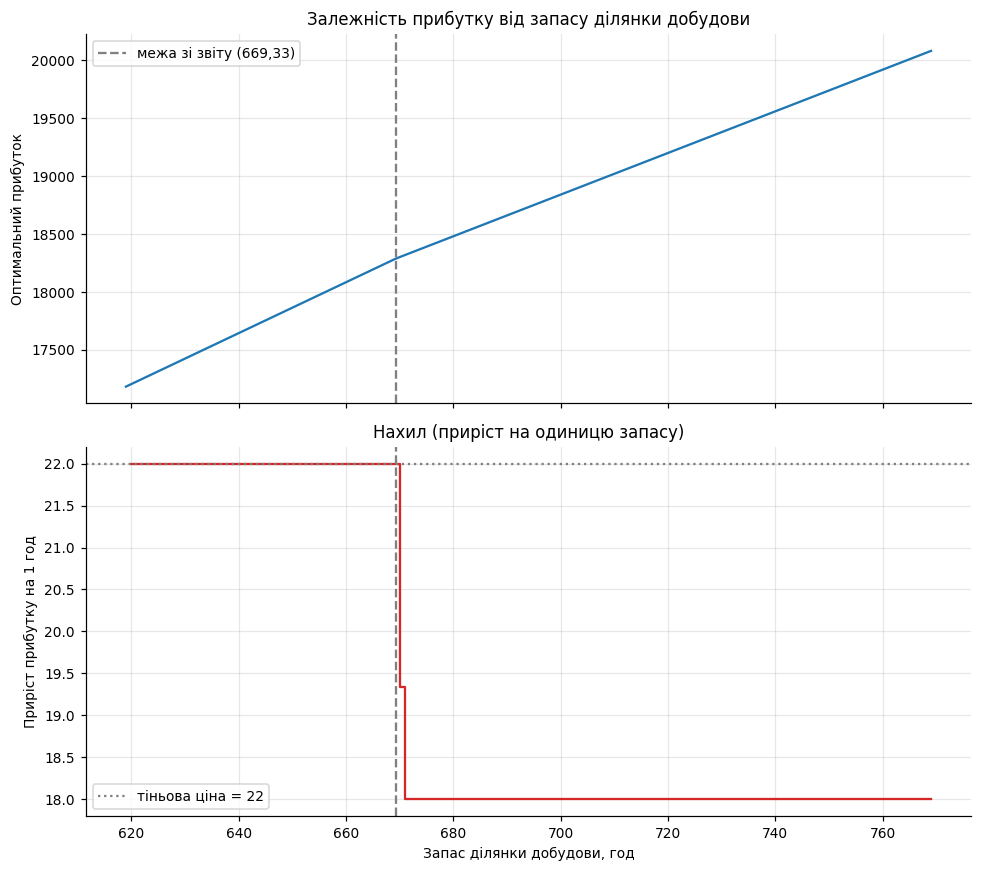

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

k = 4                      
ТІНЬОВА = 22               

запаси = np.arange(b[k], b[k] + 151, 1)

прибутки = []
for s in запаси:
    bb = b.copy()
    bb[k] = s
    r = linprog(-c, A_ub=A, b_ub=bb, bounds=(0, None), method='highs')
    прибутки.append(-r.fun)
прибутки = np.array(прибутки)
нахил = np.diff(прибутки)

i = np.where(np.abs(нахил - ТІНЬОВА) > 1e-6)[0][0]
print(f'Нахил дорівнює {ТІНЬОВА} до запасу {запаси[i]:.0f}, далі змінюється')
print(f'Межа за звітом: {b[k]} + 50.33 = {b[k] + 50.3333:.2f}')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

ax1.plot(запаси, прибутки, color='tab:blue')
ax1.axvline(b[k] + 50.3333, color='gray', linestyle='--', label='межа зі звіту (669,33)')
ax1.set_ylabel('Оптимальний прибуток')
ax1.set_title('Залежність прибутку від запасу ділянки добудови')
ax1.grid(alpha=0.3)
ax1.legend()

ax2.step(запаси[1:], нахил, where='post', color='tab:red')
ax2.axhline(ТІНЬОВА, color='gray', linestyle=':', label=f'тіньова ціна = {ТІНЬОВА}')
ax2.axvline(b[k] + 50.3333, color='gray', linestyle='--')
ax2.set_xlabel('Запас ділянки добудови, год')
ax2.set_ylabel('Приріст прибутку на 1 год')
ax2.set_title('Нахил (приріст на одиницю запасу)')
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

**Відповідь 5.2:** *(на скільки одиниць можна збільшити запас, доки тіньова ціна не зміниться;
чи збігається знайдена межа з «допустимим збільшенням» зі звіту Excel)*

>Запас ділянки добудови можна збільшити приблизно на 50,33 год (з 619 до ≈669,33), доки тіньова ціна лишається рівною 22. 
>Нахил графіка прибутку дорівнює 22 на кожному кроці до запасу 669. На кроці до 670 він падає до 19,33, а далі стабілізується на 18. Отже, тіньова ціна змінюється саме після ≈669,33.
>
>Знайдена межа збігається з «допустимим збільшенням» зі звіту Excel - у звіті для ділянки добудови допустиме збільшення дорівнює 50,33, і 619 + 50,33 = 669,33.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

>ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
>
>  ресурс: Ділянка добудови, год
>
>  ціна:   34.9 за одиницю
>
>  обсяг:  до 100 одиниць


### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
import numpy as np
from scipy.optimize import linprog

ціна = 34.9                
макс_обсяг = 100        

тіньова = 22                 
допуск_збільшення = 50.3333  

def оптимум(bb):
    r = linprog(-c, A_ub=A, b_ub=bb, bounds=(0, None), method='highs')
    return -r.fun
базовий = оптимум(b)

print(f'Ціна пропозиції: {ціна}, тіньова ціна: {тіньова}')
print('Вигідно' if ціна < тіньова else 'Невигідно', '— ціна', 'нижча' if ціна < тіньова else 'вища', 'за тіньову ціну')

print('\nОбсяг | приріст прибутку | витрати | чистий прибуток')
for q in [0, 1, 10, 25, 50, 100]:
    bb = b.copy(); bb[k] += q
    приріст = оптимум(bb) - базовий
    витрати = ціна * q
    print(f'{q:5} | {приріст:16.2f} | {витрати:7.2f} | {приріст - витрати:13.2f}')

bb = b.copy(); bb[k] += макс_обсяг
приріст_100 = оптимум(bb) - базовий
виграш_100 = приріст_100 - ціна * макс_обсяг
print(f'\nЗа формулою (тіньова ціна): {(тіньова - ціна) * макс_обсяг:.2f}')
print(f'Прямим розв\'язанням:         {виграш_100:.2f}')

Ціна пропозиції: 34.9, тіньова ціна: 22
Невигідно — ціна вища за тіньову ціну

Обсяг | приріст прибутку | витрати | чистий прибуток
    0 |             0.00 |    0.00 |          0.00
    1 |            22.00 |   34.90 |        -12.90
   10 |           220.00 |  349.00 |       -129.00
   25 |           550.00 |  872.50 |       -322.50
   50 |          1100.00 | 1745.00 |       -645.00
  100 |          2001.33 | 3490.00 |      -1488.67

За формулою (тіньова ціна): -1290.00
Прямим розв'язанням:         -1488.67


**Відповідь 6.1:**

>* Брати чи ні і чому:
>
>**Не брати.** Постачальник просить 34,9 за годину, а тіньова ціна ділянки добудови зі звіту 22. Тіньова ціна показує, скільки додаткового прибутку дає одна додаткова година : за кожну годину ми заплатили б 34,9, а отримали б не більше 22, тобто втрачали б щонайменше 12,9 на годину. Т

>* Скільки одиниць має сенс купити і чому не більше:
>
>**Не купувати.** Ціна вища за тіньову ціну вже для першої години, тож жоден обсяг не окупається. Ситуація ще гірша при великих обсягах: тіньова ціна 22 діє лише до +50,33 год, далі структура плану змінюється, і кожна нова година приносить 18. Тому навіть у межах діапазону збиток на годину складає 12,9, а за його межами зростає до 16,9. 

>* Очікуваний виграш:
>
>**Від'ємний, тобто збиток.** Якщо купити всі 100 год, за тіньовою ціною було б (22 − 34,9)·100 = −1290, але це наближення, бо 100 виходить за діапазон.

>* Перевірка прямим розв'язанням дала:
>
>При запасі 619 + 100 = 719 год оптимальний прибуток зростає з 17180,67 до 19182,00, тобто на 2001,33. Витрати на закупівлю 34,9·100 = 3490. Чистий результат 2001,33 − 3490 = −1488,67, тобто закупівля 100 год збиткова. Це гірше, ніж дає розрахунок за тіньовою ціною (−1290), бо за межею діапазону ціна ресурсу падає з 22 до 18. Розрахунок, що спирається лише на тіньову ціну, тут занадт оптимістичний, а пряме розв'язання показує реальність.

---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [11]:
import numpy as np
from scipy.optimize import linprog

eps = 1e-6                                  
ненульових = int(np.sum(np.array(r.x) > eps))  
звязних = int(np.sum(np.array(r.slack) < eps)) 

print('Випуск:', np.round(r.x, 4))
print('Залишки ресурсів:', np.round(r.slack, 4))

Випуск: [223.375  98.875   0.      0.   ]
Залишки ресурсів: [473.625  74.75  699.625   0.      0.   ]


In [12]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** *(чи збіглися числа; що означала б розбіжність на практиці)*

>Ненульовий випуск мають 2 вироби (Sting і Ray), зв'язних обмежень також 2 (столярний цех і ділянка добудови, залишок 0). 
>
>У задачі 4 змінні, тож вершина допустимої області визначається чотирма активними умовами, ними бувають або зв'язні ресурсні обмеження, або умови xⱼ = 0. Два вироби нульові, тому потрібні ще дві активні умови, і це дві зв'язні ресурсні.

>Що означала б розбіжність на практиці:
>* Зв'язних обмежень більше, ніж ненульових змінних. Це виродженість: у вершині перетинається більше площин, ніж потрібно, і тоді тіньові ціни можуть бути неоднозначними, а «Допустиме збільшення/зменшення» у звіті може вийти нульовим або оманливим. 
>* Зв'язних обмежень менше, ніж ненульових змінних. Такого при правильному симплекс-розв'язку бути не повинно - це сигнал помилки: невірно введено обмеження чи коефіцієнти, порушено невід'ємність, розв'язувач не дійшов до оптимуму або використано інше допущення.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [13]:
import numpy as np
from scipy.optimize import linprog

r_lp = linprog(-c, A_ub=A, b_ub=b, bounds=(0, None), method='highs')
x_lp, p_lp = r_lp.x, -r_lp.fun

x_round = np.round(x_lp)
споживання = A @ x_round
допустимий = bool(np.all(споживання <= b + 1e-9))
p_round = c @ x_round

r_int = linprog(-c, A_ub=A, b_ub=b, bounds=(0, None),
                integrality=np.ones(4), method='highs')
x_int, p_int = np.round(r_int.x), -r_int.fun

print(f'{"                              План":<28}{"                         Прибуток":>10}     Допустимий?')
print(f'{"без цілочисельності":<26}{str(np.round(x_lp, 2)):<28}{p_lp:>10.2f}  так')
print(f'{"округлений":<26}{str(x_round):<28}{p_round:>10.2f}  {"так" if допустимий else "НІ"}')
print(f'{"цілочисельний оптимум":<26}{str(x_int):<28}{p_int:>10.2f}  так')

print('\nСпоживання округленого плану:', споживання)
print('Запаси:  ', b)
print(f'Втрата відносно LP: {p_lp - p_int:.2f} ({(p_lp - p_int) / p_lp * 100:.2f}%)')

                              План                         Прибуток     Допустимий?
без цілочисельності       [169.22 111.33   0.     0.  ]  17180.67  так
округлений                [169. 111.   0.   0.]         17148.00  так
цілочисельний оптимум     [169. 111.   0.   0.]         17148.00  так

Споживання округленого плану: [ 671.  666.  169. 1004.  618.]
Запаси:   [1217  668  923 1040  619]
Втрата відносно LP: 32.67 (0.19%)


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | [169.22 111.33   0.     0.  ] | 17180.67 | так |
| округлений | [169. 111.   0.   0.] | 17148.00 | так |
| цілочисельний оптимум | [169. 111.   0.   0.] | 17148.00 | так |

**Висновок:** *(чи можна округлювати і чому)*

>У цьому варіанті округлення спрацювало: округлений план виявився допустимим і збігся з цілочисельним оптимумом.
>
>Так буває не завжди, і це не властивість методу, а щасливий збіг умов, округлення могло б давати:
>* Недопустимий план. Якби ми округлили 111,33 вгору до 112, то столярний цех вимагав би 6·112 = 672 > 668, а ділянка добудови 3·169 + 112 = 619, ще в межах.
>* Допустимий, але не оптимальний план. Округлення не гарантує найкращого цілого розв'язку, іноді існує інший цілий план з більшим прибутком, який не є сусідом дробового розв'язку.

---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

>* Щербан Ярина
>
>Міста постачальники : Щирець, Ерастівка, Рівне
>
>Міста споживачі : Яготин, Ромни, Ніжин, Андрушівка

| - | **Яготин** | **Ромни** | **Ніжин** | **Андрушівка** | **Запаси** |
|---|---|---|---|---|---|
| **Щирець** | 682 | 809 | 728 | 248 | **120** |
| **Ерастівка** | 372 | 368 | 416 | 771 | **150** |
| **Рівне** | 437 | 561 | 480 | 57 | **130** |
| **Попит** | **90** | **100** | **100** | **110** | **400** |


In [14]:
import numpy as np
import pandas as pd
постачальники = ['Щирець', 'Ерастівка', 'Рівне']            
споживачі     = ['Яготин', 'Ромни', 'Ніжин', 'Андрушівка']            
D = np.array([
    [682, 809, 728, 248],
    [372, 368, 416, 771],
    [437, 561, 480, 57]
])             
запас = [120, 150, 130]                   
попит = [90, 100, 100, 110]                    

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)

,Яготин,Ромни,Ніжин,Андрушівка
Щирець,682,809,728,248
Ерастівка,372,368,416,771
Рівне,437,561,480,57


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [48]:
%pip install pulp==2.8.0

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import numpy as np
import pandas as pd
import pulp

m, n = D.shape
prob = pulp.LpProblem("Transport", pulp.LpMinimize)
x = pulp.LpVariable.dicts("x", (range(m), range(n)), lowBound=0)
prob += pulp.lpSum(D[i][j] * x[i][j] for i in range(m) for j in range(n))

for i in range(m):
    prob += pulp.lpSum(x[i][j] for j in range(n)) == запас[i], f"supply_{i}"
for j in range(n):
    prob += pulp.lpSum(x[i][j] for i in range(m)) == попит[j], f"demand_{j}"

prob.solve(pulp.PULP_CBC_CMD(msg=0))

X = np.array([[x[i][j].value() for j in range(n)] for i in range(m)])
план = pd.DataFrame(np.round(X, 2), index=постачальники, columns=споживачі)
план["Разом"] = план.sum(axis=1)
план.loc["Разом"] = план.sum()

print("=" * 70)
print(f"PuLP (CBC), статус: {pulp.LpStatus[prob.status]}")
print("=" * 70)
print("\nОптимальний план перевезень:")
print(план.to_string())
print(f"\nСумарна вартість: {pulp.value(prob.objective):,.2f}")

рядки  = [(f"Запас: {постачальники[i]}", запас[i], prob.constraints[f"supply_{i}"].pi)
          for i in range(m)]
рядки += [(f"Попит: {споживачі[j]}", попит[j], prob.constraints[f"demand_{j}"].pi)
          for j in range(n)]
тіньові = pd.DataFrame(рядки, columns=["Обмеження", "Права частина", "Тіньова ціна"])

print("\nТіньові ціни обмежень:")
print(тіньові.round(4).to_string(index=False))

PuLP (CBC), статус: Optimal

Оптимальний план перевезень:
           Яготин  Ромни  Ніжин  Андрушівка  Разом
Щирець       10.0    0.0    0.0       110.0  120.0
Ерастівка    50.0  100.0    0.0         0.0  150.0
Рівне        30.0    0.0  100.0         0.0  130.0
Разом        90.0  100.0  100.0       110.0  400.0

Сумарна вартість: 150,610.00

Тіньові ціни обмежень:
        Обмеження  Права частина  Тіньова ціна
    Запас: Щирець            120         678.0
 Запас: Ерастівка            150         368.0
     Запас: Рівне            130         433.0
    Попит: Яготин             90           4.0
     Попит: Ромни            100           0.0
     Попит: Ніжин            100          47.0
Попит: Андрушівка            110        -430.0


In [16]:
import numpy as np
import pandas as pd
from scipy.optimize import linprog

m, n = D.shape
c = D.flatten()                    
A_eq = np.zeros((m + n, m * n))
for i in range(m):
    A_eq[i, i * n:(i + 1) * n] = 1     
for j in range(n):
    A_eq[m + j, j::n] = 1             
b_eq = np.array(запас + попит, dtype=float)

res = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method="highs")

X = res.x.reshape(m, n)
план = pd.DataFrame(np.round(X, 2), index=постачальники, columns=споживачі)
план["Разом"] = план.sum(axis=1)
план.loc["Разом"] = план.sum()

print("=" * 70)
print(f"scipy.linprog (HiGHS), статус: {res.message}")
print("=" * 70)
print("\nОптимальний план перевезень:")
print(план.to_string())
print(f"\nСумарна вартість: {res.fun:,.2f}")

марг = res.eqlin.marginals
рядки  = [(f"Запас: {постачальники[i]}", запас[i], марг[i]) for i in range(m)]
рядки += [(f"Попит: {споживачі[j]}", попит[j], марг[m + j]) for j in range(n)]
тіньові = pd.DataFrame(рядки, columns=["Обмеження", "Права частина", "Тіньова ціна"])

print("\nТіньові ціни обмежень:")
print(тіньові.round(4).to_string(index=False))

scipy.linprog (HiGHS), статус: Optimization terminated successfully. (HiGHS Status 7: Optimal)

Оптимальний план перевезень:
           Яготин  Ромни  Ніжин  Андрушівка  Разом
Щирець       10.0    0.0    0.0       110.0  120.0
Ерастівка    50.0  100.0    0.0         0.0  150.0
Рівне        30.0    0.0  100.0         0.0  130.0
Разом        90.0  100.0  100.0       110.0  400.0

Сумарна вартість: 150,610.00

Тіньові ціни обмежень:
        Обмеження  Права частина  Тіньова ціна
    Запас: Щирець            120          -0.0
 Запас: Ерастівка            150        -310.0
     Запас: Рівне            130        -245.0
    Попит: Яготин             90         682.0
     Попит: Ромни            100         678.0
     Попит: Ніжин            100         725.0
Попит: Андрушівка            110         248.0


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [17]:
тіні_pulp = ([prob.constraints[f"supply_{i}"].pi for i in range(m)] +
             [prob.constraints[f"demand_{j}"].pi for j in range(n)])
тіні_scipy = list(res.eqlin.marginals)

назви = ([f"Запас: {p}" for p in постачальники] +
         [f"Попит: {s}" for s in споживачі])

порівняння = pd.DataFrame({
    "Обмеження": назви,
    "Права частина": запас + попит,
    "PuLP": тіні_pulp,
    "linprog": тіні_scipy,
})
порівняння["Різниця (PuLP − linprog)"] = порівняння["PuLP"] - порівняння["linprog"]

print("=" * 75)
print("ПОРІВНЯННЯ ТІНЬОВИХ ЦІН: PuLP vs scipy.linprog")
print("=" * 75)
print(f"Вартість PuLP:    {pulp.value(prob.objective):,.2f}")
print(f"Вартість linprog: {res.fun:,.2f}\n")
print(порівняння.round(4).to_string(index=False))

різн_запас = порівняння["Різниця (PuLP − linprog)"][:m].round(6).unique()
різн_попит = порівняння["Різниця (PuLP − linprog)"][m:].round(6).unique()
print(f"\nРізниця для запасів: {різн_запас}")
print(f"Різниця для попитів: {різн_попит}")

ПОРІВНЯННЯ ТІНЬОВИХ ЦІН: PuLP vs scipy.linprog
Вартість PuLP:    150,610.00
Вартість linprog: 150,610.00

        Обмеження  Права частина   PuLP  linprog  Різниця (PuLP − linprog)
    Запас: Щирець            120  678.0     -0.0                     678.0
 Запас: Ерастівка            150  368.0   -310.0                     678.0
     Запас: Рівне            130  433.0   -245.0                     678.0
    Попит: Яготин             90    4.0    682.0                    -678.0
     Попит: Ромни            100    0.0    678.0                    -678.0
     Попит: Ніжин            100   47.0    725.0                    -678.0
Попит: Андрушівка            110 -430.0    248.0                    -678.0

Різниця для запасів: [678.]
Різниця для попитів: [-678.]


**Відповідь 10.2:**

>* Вартість у двох розв'язувачів:
>Однакова : 150,610.00

>* Тіньові ціни збіглися чи ні:
>Різниця однакова в межах групи: у всіх запасів вона +678, у всіх попитів −678. 
>Тобто PuLP = linprog + 678 для запасів і PuLP = linprog − 678 для попитів - це і є ефект «зсуву на константу k».

>* Яку закономірність ви побачили в різниці:
>Задача збалансована (Σ запас = Σ попит = 400), тому одне з 7 обмежень надлишкове: якщо виконано 6, сьомe виконується автоматично. Через це двоїста задача має нескінченно багато розв'язків виду (uᵢ + k, vⱼ − k), а двоїста вартість від k не залежить: k · (Σ запас − Σ попит) = k · 0 = 0. 
>Розв'язувач просто обирає одну «нормалізацію»:
>
>* linprog зафіксував u(Щирець) = 0
>* PuLP зафіксував v(Ромни) = 0

>* Що це означає для того, хто збирається ухвалювати рішення за цим звітом:
>1. Тіньова ціна показує, наскільки зміниться загальна вартість, якщо змінити запас або попит на одиницю. Але в нашій задачі запас і попит однакові (400 = 400), тому програма може «зсунути» всі числа на одну й ту саму величину, і результат не зміниться. Через це два розв'язувачі дали різні числа - наприклад, для Андрушівки PuLP показав −430, а linprog показав +248.
>
>2. Що можна порівнювати: суму «запас + попит»
>Число, яке не залежить від «точки відліку», отримуємо, якщо додати тіньову ціну запасу одного пункту й тіньову ціну попиту іншого - воно відповідає на питання: «Скільки коштуватиме довезти ще одну одиницю з пункту А в пункт Б, якщо все перерозподілити якнайкраще?»

>* Ерастівка → Ромни: −310 + 678 = 368. Це дорівнює прямій відстані (368), бо цей маршрут уже є в плані, і додаткова одиниця їде саме ним.
>* Рівне → Андрушівка: −245 + 248 = 3. А пряма відстань між ними 57. Виходить, що додаткову одиницю вигідніше довезти не напряму, а в обхід через перерозподіл.
>
>Рівне відправляє ще 1 одиницю в Яготин	+437
>Щирець відправляє в Яготин на 1 одиницю менше	−682
>Щирець відправляє в Андрушівку на 1 одиницю більше	+248
>Разом	+3
>
>Тобто Яготин отримує ту саму кількість (тільки тепер із Рівного, а не зі Щирця), а звільнена одиниця зі Щирця їде в Андрушівку. Загалом це коштує всього 3 замість 57.

---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [18]:
m, n = D.shape
c = D.flatten()
A_eq = np.zeros((m + n, m * n))
for i in range(m):
    A_eq[i, i * n:(i + 1) * n] = 1
for j in range(n):
    A_eq[m + j, j::n] = 1
b_eq = np.array(запас + попит, dtype=float)

res = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method="highs")
x = res.x

tol = 1e-9
ненульових_1 = int(np.sum(x > tol))

нев_язка = A_eq @ x - b_eq
зв_язних_1 = int(np.sum(np.abs(нев_язка) < 1e-7))

ранг = np.linalg.matrix_rank(A_eq)

print(f"Ненульових перевезень: {ненульових_1}")
print(f"Зв'язних обмежень:     {зв_язних_1} із {m + n}")
print(f"Ранг матриці обмежень: {ранг}")
print(f"Різниця (обмежень − ненульових): {m + n - ненульових_1}")

Ненульових перевезень: 6
Зв'язних обмежень:     7 із 7
Ранг матриці обмежень: 6
Різниця (обмежень − ненульових): 1


**Відповідь 11.1:**

>* Ненульових перевезень: **6**
>* Зв'язних обмежень: **7**

>* Чому в транспортній задачі зв'язними виявляються **всі** обмеження:
>
>Усі 7 обмежень задані рівностями і вони виконуються завжди, тому нев'язка A·x − b дорівнює нулю для кожного з них. Для нерівностей типу «≤» частина обмежень могла б мати запас і бути незв'язною.

>* На скільки ненульових перевезень менше і чому саме на стільки:
>
>Менше на **1**: 7 − 6 = 1. Причина в тому, що 7 обмежень не є незалежними, якщо додати всі рівняння запасів, вийде те саме, що при додаванні всіх рівнянь попитів: 400 = 400. Тому одне обмеження випливає з інших шести, і ранг дорівнює 3 + 4 − 1 = 6. 
>
>Вершина допустимої області (базисний розв'язок) має не більше стільки ненульових змінних, скільки дорівнює ранг, тобто не більше 6. Тут їх рівно 6, тож розв'язок невироджений, а якби нулів було більше (якийсь маршрут із базису мав би обсяг 0), розв'язок був би виродженим.

### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

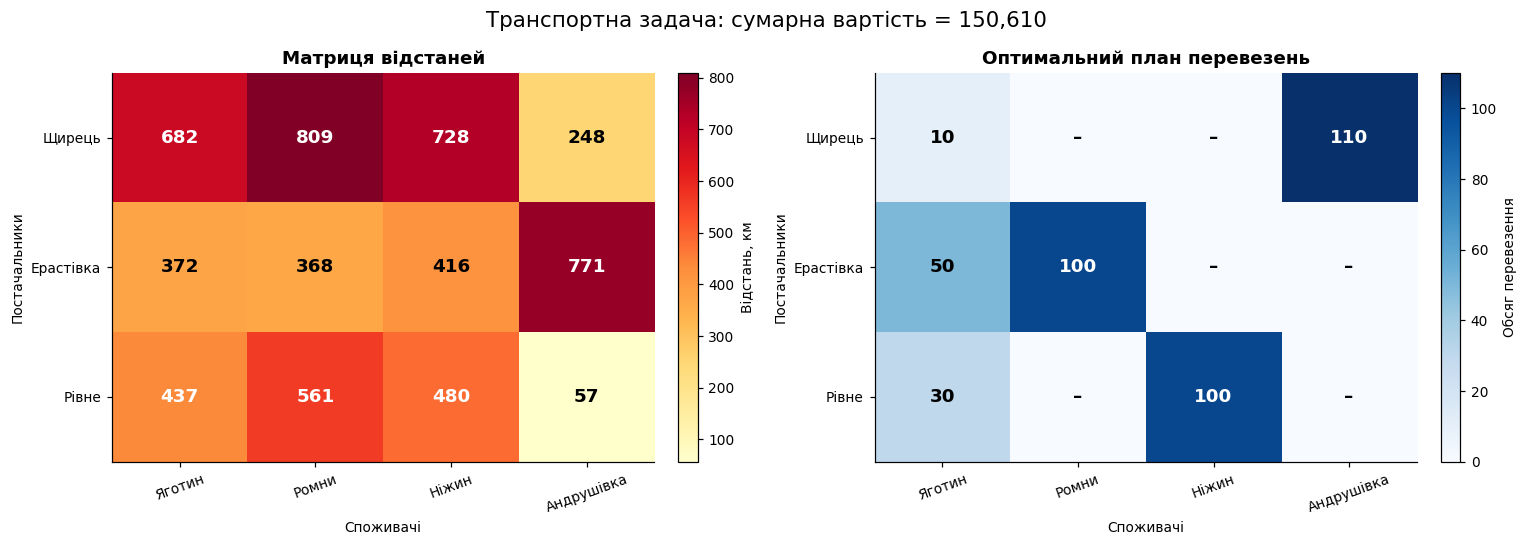

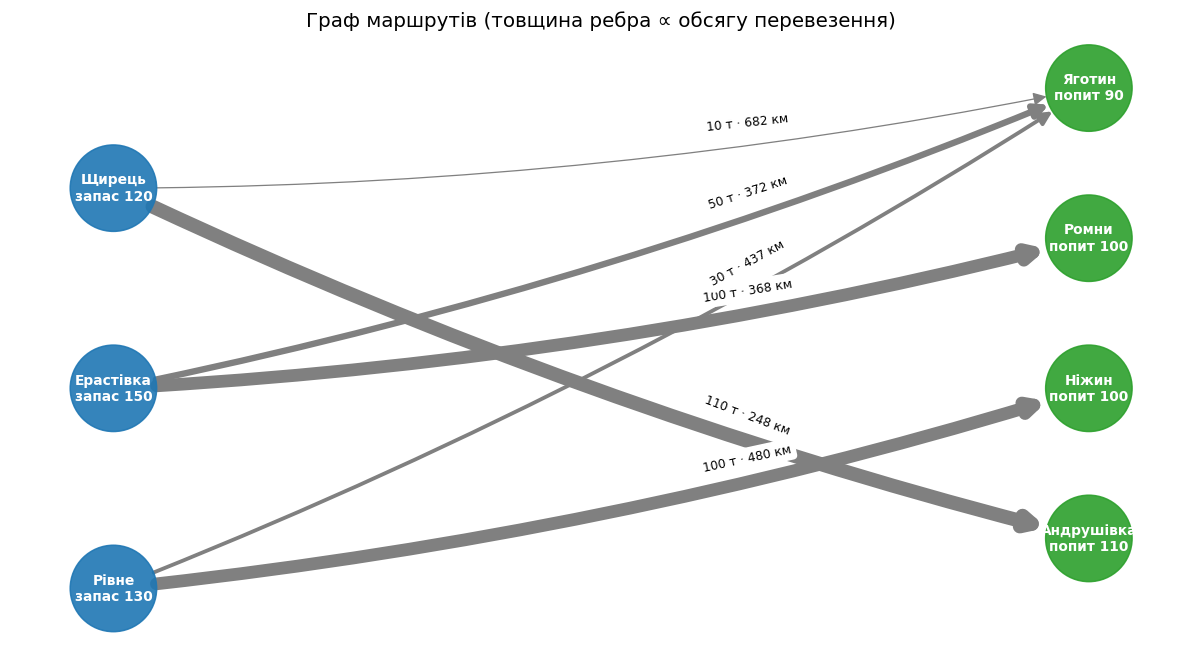

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import linprog

c = D.flatten()
A_eq = np.zeros((m + n, m * n))
for i in range(m):
    A_eq[i, i * n:(i + 1) * n] = 1
for j in range(n):
    A_eq[m + j, j::n] = 1
b_eq = np.array(запас + попит, dtype=float)

res = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=(0, None), method="highs")
X = np.round(res.x.reshape(m, n), 6)

def теплова_карта(ax, M, назва, cmap, формат, підпис_шкали):
    im = ax.imshow(M, cmap=cmap, aspect="auto")
    ax.set_xticks(range(n))
    ax.set_xticklabels(споживачі, rotation=20)
    ax.set_yticks(range(m))
    ax.set_yticklabels(постачальники)
    ax.set_xlabel("Споживачі")
    ax.set_ylabel("Постачальники")
    ax.set_title(назва, fontsize=12, fontweight="bold")
    межа = (M.max() + M.min()) / 2
    for i in range(m):
        for j in range(n):
            колір = "white" if M[i, j] > межа else "black"
            ax.text(j, i, формат(M[i, j]), ha="center", va="center",
                    color=колір, fontsize=12, fontweight="bold")
    plt.colorbar(im, ax=ax, label=підпис_шкали, fraction=0.046, pad=0.04)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
теплова_карта(axes[0], D.astype(float), "Матриця відстаней", "YlOrRd",
              lambda v: f"{v:.0f}", "Відстань, км")
теплова_карта(axes[1], X, "Оптимальний план перевезень", "Blues",
              lambda v: f"{v:.0f}" if v > 1e-9 else "–", "Обсяг перевезення")
fig.suptitle(f"Транспортна задача: сумарна вартість = {res.fun:,.0f}", fontsize=14)
plt.tight_layout()
plt.show()

G = nx.DiGraph()
позиції = {}
for i, p in enumerate(постачальники):
    G.add_node(p)
    позиції[p] = (0, -i * 2 - 1)
for j, s in enumerate(споживачі):
    G.add_node(s)
    позиції[s] = (3, -j * 1.5)

for i in range(m):
    for j in range(n):
        if X[i, j] > 1e-9:
            G.add_edge(постачальники[i], споживачі[j], обсяг=X[i, j])

ширини = [G[u][v]["обсяг"] / 12 for u, v in G.edges()]
кольори = ["#1f77b4"] * m + ["#2ca02c"] * n
підписи_вузлів = {
    **{p: f"{p}\nзапас {запас[i]}" for i, p in enumerate(постачальники)},
    **{s: f"{s}\nпопит {попит[j]}" for j, s in enumerate(споживачі)},
}

plt.figure(figsize=(11, 6))
nx.draw_networkx_nodes(G, позиції, node_color=кольори, node_size=3200, alpha=0.9)
nx.draw_networkx_labels(G, позиції, labels=підписи_вузлів, font_size=9,
                        font_color="white", font_weight="bold")
nx.draw_networkx_edges(G, позиції, width=ширини, edge_color="gray",
                       arrows=True, arrowsize=18, node_size=3200,
                       connectionstyle="arc3,rad=0.05")
підписи_ребер = {(u, v): f"{G[u][v]['обсяг']:.0f} т · {D[постачальники.index(u)][споживачі.index(v)]} км"
                 for u, v in G.edges()}
nx.draw_networkx_edge_labels(G, позиції, edge_labels=підписи_ребер, font_size=8,
                             label_pos=0.35)
plt.title("Граф маршрутів (товщина ребра ∝ обсягу перевезення)", fontsize=13)
plt.axis("off")
plt.tight_layout()
plt.show()

**Висновок:** *(одне речення про те, що видно на теплових картах)*

>Найкоротший маршрут у всій матриці, Рівне → Андрушівка (57 км), у плані не використовується. Причина в тому, що запас Рівного (130) потрібен, щоб закрити попит Ніжина (100 через 480 км) і частину Яготина (30). Для Ніжина немає дешевшої альтернативи, яка б не збільшила загальну вартість. Використання маршруту Рівне → Андрушівка примусово збільшило б вартість на 54 за кожну одиницю.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [20]:
ІНСТРУМЕНТИ_ШІ = 'Gemini'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'ні',
    'етап 2, побудова моделі в Excel':      'ні',
    'етап 3, код на Python':                'ні',
    'етапи 4–5, читання та перевірка звіту': 'синтаксис',
    'етап 6, рішення про закупівлю':        'синтаксис',
    'етапи 7–8, перевірка та цілочисельність': 'синтаксис',
    'етапи 9–11, транспортна задача':       'синтаксис',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = 'Використовувала для генерації графіків, а також питалась щодо випадків, коли кількість ненульових змінних не збігається із кількістю зв’язних обмежень. '

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [21]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Щербан Ярина Олегівна
інструменти:                               Gemini
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           ні
етап 3, код на Python:                     ні
етапи 4–5, читання та перевірка звіту:     синтаксис
етап 6, рішення про закупівлю:             синтаксис
етапи 7–8, перевірка та цілочисельність:   синтаксис
етапи 9–11, транспортна задача:            синтаксис
------------------------------------------------------------------------------
Використовувала для генерації графіків, а також питалась щодо випадків, коли кількість ненульових змінних не збігається із кількістю зв’язних обмежень. 


---
# Крок 13. Фінальна самоперевірка

In [22]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
